In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler, MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.feature_selection import SelectKBest, mutual_info_regression

from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
df = pd.read_csv("crop_yield.csv")
print("Data loaded successfully!")
print("\nFirst 5 rows:")
print(df.head())

Data loaded successfully!

First 5 rows:
           Crop  Crop_Year       Season  State     Area  Production  \
0      Arecanut       1997  Whole Year   Assam  73814.0       56708   
1     Arhar/Tur       1997  Kharif       Assam   6637.0        4685   
2   Castor seed       1997  Kharif       Assam    796.0          22   
3      Coconut        1997  Whole Year   Assam  19656.0   126905000   
4  Cotton(lint)       1997  Kharif       Assam   1739.0         794   

   Annual_Rainfall  Fertilizer  Pesticide        Yield  
0           2051.4  7024878.38   22882.34     0.796087  
1           2051.4   631643.29    2057.47     0.710435  
2           2051.4    75755.32     246.76     0.238333  
3           2051.4  1870661.52    6093.36  5238.051739  
4           2051.4   165500.63     539.09     0.420909  


In [3]:
print("\nShape of dataset:")
print(df.shape)


Shape of dataset:
(19689, 10)


In [4]:
print("\n================ DATA PROFILING ================")
# Shape
print("\n1. Shape:")
print(df.shape)


================ DATA PROFILING ================

1. Shape:
(19689, 10)


In [5]:
print("\n2. Data Types:")
print(df.dtypes)


2. Data Types:
Crop                   str
Crop_Year            int64
Season                 str
State                  str
Area               float64
Production           int64
Annual_Rainfall    float64
Fertilizer         float64
Pesticide          float64
Yield              float64
dtype: object


In [6]:
print("\n3. Descriptive Statistics:")
print(df.describe())


3. Descriptive Statistics:
          Crop_Year          Area    Production  Annual_Rainfall  \
count  19689.000000  1.968900e+04  1.968900e+04     19689.000000   
mean    2009.127584  1.799266e+05  1.643594e+07      1437.755177   
std        6.498099  7.328287e+05  2.630568e+08       816.909589   
min     1997.000000  5.000000e-01  0.000000e+00       301.300000   
25%     2004.000000  1.390000e+03  1.393000e+03       940.700000   
50%     2010.000000  9.317000e+03  1.380400e+04      1247.600000   
75%     2015.000000  7.511200e+04  1.227180e+05      1643.700000   
max     2020.000000  5.080810e+07  6.326000e+09      6552.700000   

         Fertilizer     Pesticide         Yield  
count  1.968900e+04  1.968900e+04  19689.000000  
mean   2.410331e+07  4.884835e+04     79.954009  
std    9.494600e+07  2.132874e+05    878.306193  
min    5.417000e+01  9.000000e-02      0.000000  
25%    1.880146e+05  3.567000e+02      0.600000  
50%    1.234957e+06  2.421900e+03      1.030000  
75%    1.

In [7]:
print("\n4. Missing Values:")
print(df.isnull().sum())


4. Missing Values:
Crop               0
Crop_Year          0
Season             0
State              0
Area               0
Production         0
Annual_Rainfall    0
Fertilizer         0
Pesticide          0
Yield              0
dtype: int64


In [8]:
print("\n5. Duplicate Records:")
print(df.duplicated().sum())


5. Duplicate Records:
0


In [10]:
print("\n================ DATA CLEANING ================")
data = df.copy()

# 4.1 Remove extra spaces / inconsistent categorical values
categorical_columns = ["Crop", "Season", "State"]

for col in categorical_columns:

    data[col] = (
        data[col]
        .astype(str)
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
    )


================ DATA CLEANING ================


In [11]:
# 4.2 Convert numerical columns to numeric

numeric_columns = [
    "Crop_Year",
    "Area",
    "Production",
    "Annual_Rainfall",
    "Fertilizer",
    "Pesticide",
    "Yield"
]

for col in numeric_columns:

    data[col] = pd.to_numeric(
        data[col],
        errors="coerce"
    )

In [12]:
# 4.3 Handle invalid negative values
non_negative_columns = [
    "Area",
    "Production",
    "Annual_Rainfall",
    "Fertilizer",
    "Pesticide",
    "Yield"
]

for col in non_negative_columns:

    data.loc[data[col] < 0, col] = np.nan


In [13]:
# 4.4 Check valid year
data = data[
    (data["Crop_Year"] >= 1900) &
    (data["Crop_Year"] <= 2100)
]

In [14]:
# 4.5 Missing-value treatment

# Numerical columns -> median
for col in numeric_columns:

    data[col] = data[col].fillna(
        data[col].median()
    )

# Categorical columns -> mode
for col in categorical_columns:

    data[col] = data[col].fillna(
        data[col].mode()[0]
    )

In [15]:
# 4.6 Duplicate removal
before_duplicates = len(data)

data = data.drop_duplicates()

after_duplicates = len(data)

print("\nDuplicates removed:",
      before_duplicates - after_duplicates)


print("\nMissing values after cleaning:")
print(data.isnull().sum())


print("\nShape after cleaning:")
print(data.shape)


Duplicates removed: 0

Missing values after cleaning:
Crop               0
Crop_Year          0
Season             0
State              0
Area               0
Production         0
Annual_Rainfall    0
Fertilizer         0
Pesticide          0
Yield              0
dtype: int64

Shape after cleaning:
(19689, 10)


In [16]:
#5. SEPARATE FEATURES AND TARGET
X = data.drop("Yield", axis=1)

y = data["Yield"]

print("\nFeatures:")
print(X.columns.tolist())

print("\nTarget: Yield")


Features:
['Crop', 'Crop_Year', 'Season', 'State', 'Area', 'Production', 'Annual_Rainfall', 'Fertilizer', 'Pesticide']

Target: Yield


In [17]:
# 6. TRAIN-TEST SPLIT
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [18]:
print("\n================ TRAIN TEST SPLIT ================")

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

print("y_train:", y_train.shape)
print("y_test :", y_test.shape)


================ TRAIN TEST SPLIT ================
X_train: (15751, 9)
X_test : (3938, 9)
y_train: (15751,)
y_test : (3938,)


In [19]:
# 7. OUTLIER DETECTION AND TREATMENT
print("\n================ OUTLIER DETECTION ================")

outlier_columns = [
    "Area",
    "Production",
    "Annual_Rainfall",
    "Fertilizer",
    "Pesticide"
]


================ OUTLIER DETECTION ================


In [20]:
outlier_limits = {}

for col in outlier_columns:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outlier_limits[col] = (lower, upper)
    print(
        col,
        "-> Lower:",
        lower,
        "Upper:",
        upper
    )

Area -> Lower: -109112.75 Upper: 185513.25
Production -> Lower: -179324.75 Upper: 302589.25
Annual_Rainfall -> Lower: -102.10000000000014 Upper: 2678.7000000000003
Fertilizer -> Lower: -14511508.274999999 Upper: 24676121.604999997
Pesticide -> Lower: -29212.760000000006 Upper: 49617.36000000001


In [21]:
# Outlier treatment using clipping
for col in outlier_columns:
    lower, upper = outlier_limits[col]
    X_train[col] = X_train[col].clip(
        lower,
        upper
    )
    X_test[col] = X_test[col].clip(
        lower,
        upper
    )
print("\nOutliers treated using IQR clipping.")


Outliers treated using IQR clipping.


In [22]:
print("\n================ CATEGORICAL ENCODING ================")
# 8.1 LABEL ENCODING
label_encoder = LabelEncoder()

X_train["Season"] = label_encoder.fit_transform(
    X_train["Season"]
)

# Handle unseen values safely
season_mapping = {
    label: index
    for index, label
    in enumerate(label_encoder.classes_)
}

X_test["Season"] = X_test["Season"].map(
    season_mapping
).fillna(-1)


print("\nSeason after Label Encoding:")
print(X_train["Season"].head())



================ CATEGORICAL ENCODING ================

Season after Label Encoding:
19466    1
17802    1
7014     4
14078    2
8121     1
Name: Season, dtype: int64


In [23]:
# 8.2 ONE-HOT ENCODING
# Crop and State are converted using One-Hot Encoding.
categorical_features = [
    "Crop",
    "State"
]

numerical_features = [
    "Crop_Year",
    "Area",
    "Production",
    "Annual_Rainfall",
    "Fertilizer",
    "Pesticide",
    "Season"
]


In [24]:
print("\n================ FEATURE SCALING ================")
# Standardization:
preprocessor = ColumnTransformer(

    transformers=[

        (
            "numerical",

            Pipeline([
                (
                    "imputer",
                    SimpleImputer(strategy="median")
                ),

                (
                    "scaler",
                    StandardScaler()
                )
            ]),

            numerical_features
        ),

        (
            "categorical",

            Pipeline([
                (
                    "imputer",
                    SimpleImputer(
                        strategy="most_frequent"
                    )
                ),

                (
                    "onehot",
                    OneHotEncoder(
                        handle_unknown="ignore",
                        sparse_output=False
                    )
                )
            ]),

            categorical_features
        )
    ],

    verbose_feature_names_out=False
)


# Fit ONLY on training data
X_train_processed = preprocessor.fit_transform(
    X_train
)

# Transform test data
X_test_processed = preprocessor.transform(
    X_test
)


print(
    "\nShape after encoding and scaling:"
)

print(
    "X_train:",
    X_train_processed.shape
)

print(
    "X_test:",
    X_test_processed.shape
)




================ FEATURE SCALING ================

Shape after encoding and scaling:
X_train: (15751, 92)
X_test: (3938, 92)


In [25]:
# 10. FEATURE SELECTION
print("\n================ FEATURE SELECTION ================")

# Get feature names
feature_names = (
    preprocessor
    .get_feature_names_out()
)

print(
    "\nTotal features before selection:",
    len(feature_names)
)


================ FEATURE SELECTION ================

Total features before selection: 92


In [26]:
k = min(20, X_train_processed.shape[1])

selector = SelectKBest(
    score_func=mutual_info_regression,
    k=k
)
X_train_selected = selector.fit_transform(
    X_train_processed,
    y_train
)
X_test_selected = selector.transform(
    X_test_processed
)
selected_features = feature_names[
    selector.get_support()
]
print(
    "\nSelected features:"
)
for feature in selected_features:
    print(feature)
print(
    "\nFeatures after selection:",
    X_train_selected.shape[1]
)


Selected features:
Area
Production
Annual_Rainfall
Fertilizer
Pesticide
Season
Crop_Banana
Crop_Coconut
Crop_Maize
Crop_Moong(Green Gram)
Crop_Onion
Crop_Potato
Crop_Rice
Crop_Sesamum
Crop_Sugarcane
Crop_Sweet potato
Crop_Tapioca
State_Assam
State_Chhattisgarh
State_Puducherry

Features after selection: 20


In [28]:
# 11. MODEL TRAINING
print("\n================ MODEL TRAINING ================")
model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)
model.fit(
    X_train_selected,
    y_train
)
print("Random Forest model trained successfully!")


================ MODEL TRAINING ================
Random Forest model trained successfully!


In [29]:
print("\n================ TESTING ================")

# Predict yield for unseen test data

y_pred = model.predict(
    X_test_selected
)
print("\nActual vs Predicted:")
comparison = pd.DataFrame({
    "Actual Yield": y_test.values[:10],
    "Predicted Yield": y_pred[:10]

})
print(comparison)


================ TESTING ================

Actual vs Predicted:
   Actual Yield  Predicted Yield
0      3.820000         5.614474
1      1.395357         1.239696
2      6.522727         6.575501
3      0.812857         1.054702
4      0.508000         0.552880
5      0.358000         0.350289
6      0.749091         0.798909
7      1.835789         1.850161
8     75.314375        58.251973
9      1.775000         2.053692


In [30]:
print("\n================ MODEL EVALUATION ================")
# MAE
mae = mean_absolute_error(
    y_test,
    y_pred
)
# MSE
mse = mean_squared_error(
    y_test,
    y_pred
)
# RMSE
rmse = np.sqrt(mse)
# R2
r2 = r2_score(
    y_test,
    y_pred
)
print("\nMean Absolute Error (MAE):")
print(mae)
print("\nMean Squared Error (MSE):")
print(mse)
print("\nRoot Mean Squared Error (RMSE):")
print(rmse)
print("\nR2 Score:")
print(r2)



================ MODEL EVALUATION ================

Mean Absolute Error (MAE):
11.65598658167086

Mean Squared Error (MSE):
27948.833772109418

Root Mean Squared Error (RMSE):
167.17904704869392

R2 Score:
0.9651180189651294


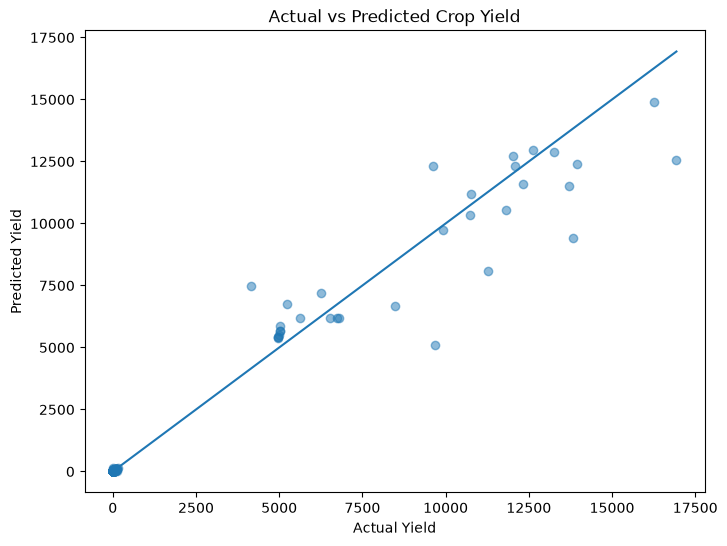

In [31]:
# 14. ACTUAL VS PREDICTED GRAPH
plt.figure(figsize=(8, 6))
plt.scatter(
    y_test,
    y_pred,
    alpha=0.5
)
plt.xlabel("Actual Yield")
plt.ylabel("Predicted Yield")
plt.title(
    "Actual vs Predicted Crop Yield"
)
# Perfect prediction line
min_value = min(
    y_test.min(),
    y_pred.min()
)
max_value = max(
    y_test.max(),
    y_pred.max()
)
plt.plot(
    [min_value, max_value],
    [min_value, max_value]
)
plt.show()

In [32]:
# 15. FINAL CLEANED DATASET GENERATION
print(
    "\n================ FINAL DATASET GENERATION ================"
)
# Create copy of complete cleaned dataset
X_all = data.drop(
    "Yield",
    axis=1
).copy()

# Apply same outlier limits
for col in outlier_columns:
    lower, upper = outlier_limits[col]
    X_all[col] = X_all[col].clip(
        lower,
        upper
    )

# Apply Label Encoding to Season
X_all["Season"] = X_all["Season"].map(
    season_mapping
).fillna(-1)

# Transform complete dataset
X_all_processed = preprocessor.transform(
    X_all
)

# Feature selection
X_all_selected = selector.transform(
    X_all_processed
)

# Create final DataFrame
final_dataset = pd.DataFrame(
    X_all_selected,
    columns=selected_features
)

# Add target column
final_dataset["Yield"] = data[
    "Yield"
].values

print("\nFinal cleaned dataset shape:")
print(final_dataset.shape)
print("\nFinal cleaned dataset:")
print(final_dataset.head())


================ FINAL DATASET GENERATION ================

Final cleaned dataset shape:
(19689, 21)

Final cleaned dataset:
       Area  Production  Annual_Rainfall  Fertilizer  Pesticide    Season  \
0  0.358780   -0.205865         1.122661    0.055398   0.536867  1.601401   
1 -0.616872   -0.658390         1.122661   -0.644562  -0.597914 -0.850832   
2 -0.701705   -0.698951         1.122661   -0.705423  -0.696583 -0.850832   
3 -0.427790    1.932945         1.122661   -0.508908  -0.377992  1.601401   
4 -0.688009   -0.692236         1.122661   -0.695597  -0.680653 -0.850832   

   Crop_Banana  Crop_Coconut  Crop_Maize  Crop_Moong(Green Gram)  ...  \
0          0.0           0.0         0.0                     0.0  ...   
1          0.0           0.0         0.0                     0.0  ...   
2          0.0           0.0         0.0                     0.0  ...   
3          0.0           1.0         0.0                     0.0  ...   
4          0.0           0.0         0.0      

In [33]:
# 16. SAVE FINAL DATASET
final_dataset.to_csv(
    "final_cleaned_crop_yield.csv",
    index=False
)
print("\nFinal dataset saved as:")
print("final_cleaned_crop_yield.csv")


Final dataset saved as:
final_cleaned_crop_yield.csv
